# BRFSS 2015 · classer les réponses à une enquête de santé

Peut-on classer les personnes qui déclarent un prédiabète ou un diabète devant les autres répondants ? La classe positive est minoritaire. Le critère principal sera la **précision moyenne (AP)**, qui évalue le classement sur plusieurs seuils.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ml_workflow as mlw

mlw.get_environment_info()

{'python': '3.12.14',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2'}

## 1. Data import and exploration

In [2]:
DATA_PATH = Path("datasets/dbh/diabetes_binary_health_indicators_BRFSS2015.csv")
X, y = mlw.load_dataset("DHI", DATA_PATH, "Diabetes_binary")

253,680 observations, 21 features
Missing feature values: 0


,count,mean,std,min,25%,50%,75%,max,dtype,missing
HighBP,253680.0,0.429,0.495,0.0,0.0,0.0,1.0,1.0,float64,0
BMI,253680.0,28.382,6.609,12.0,24.0,27.0,31.0,98.0,float64,0
GenHlth,253680.0,2.511,1.068,1.0,2.0,2.0,3.0,5.0,float64,0
Age,253680.0,8.032,3.054,1.0,6.0,8.0,10.0,13.0,float64,0
Education,253680.0,5.050,0.986,1.0,4.0,5.0,6.0,6.0,float64,0
Income,253680.0,6.054,2.071,1.0,5.0,7.0,8.0,8.0,float64,0


,count,proportion
Diabetes_binary,,
0.000000,218334,86.1%
1.000000,35346,13.9%


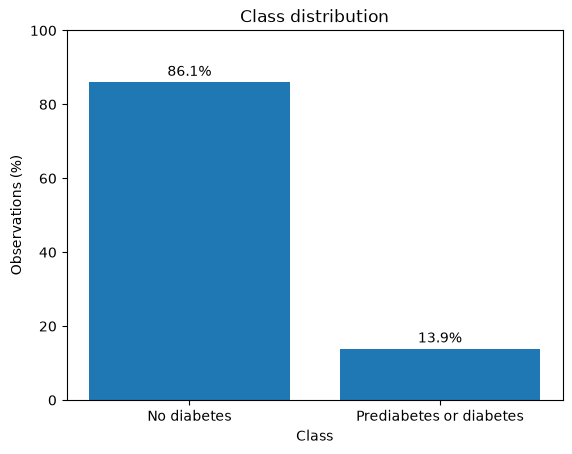

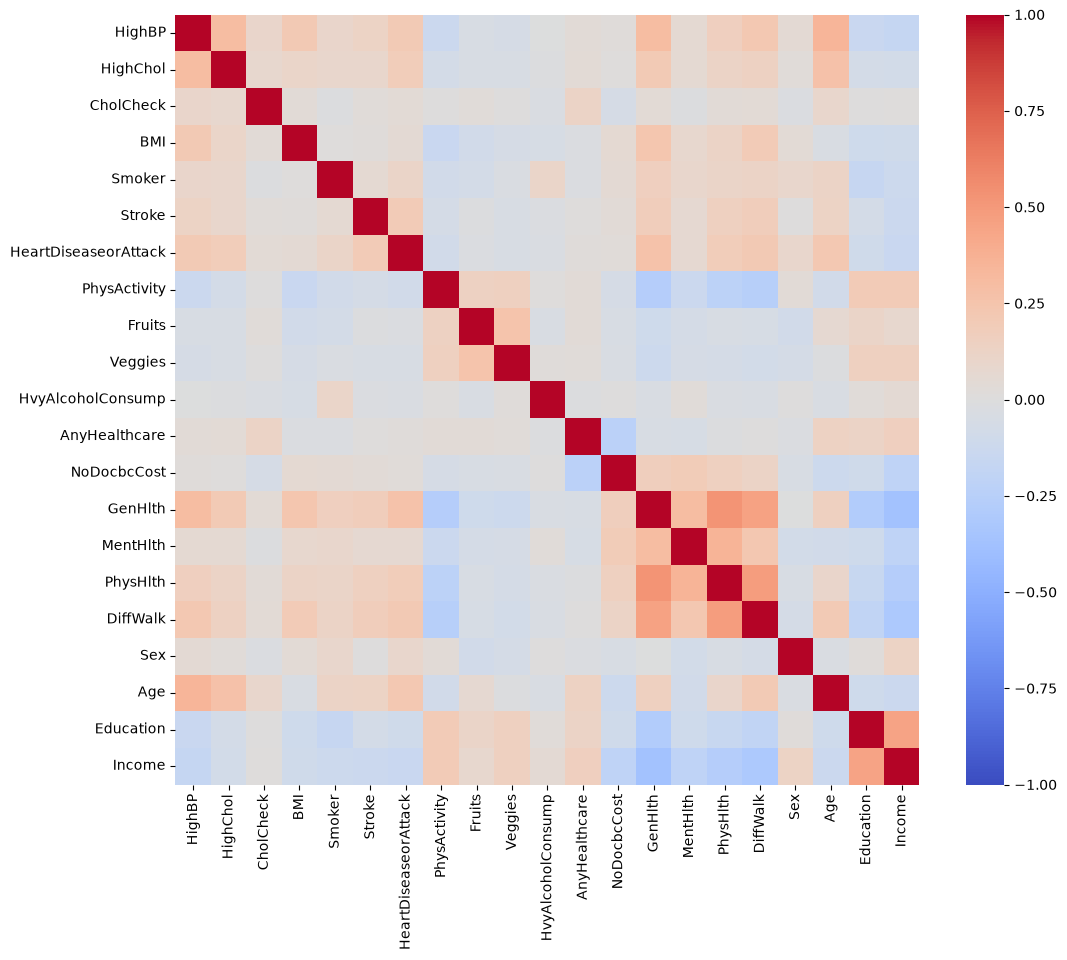

In [3]:
print(f"{X.shape[0]:,} observations, {X.shape[1]} features")
summary = mlw.summarize_dataset(X)
print("Missing feature values:", summary["missing"].sum())
display(summary.loc[['HighBP', 'BMI', 'GenHlth', 'Age', 'Education', 'Income']].round(3))

distribution = mlw.get_class_distribution(y)
display(distribution.style.format({"proportion": "{:.1%}"}))
mlw.plot_class_distribution(y, labels={0: "No diabetes", 1: "Prediabetes or diabetes"})
plt.show()

mlw.plot_correlation_matrix(X)
plt.show()

**Commentaire :** Sur 253 680 observations, 35 346 appartiennent à la classe positive (13,9 %). Prédire systématiquement la classe négative donnerait déjà 86,1 % d’exactitude, avec un rappel nul pour les cas positifs. Nous suivrons donc le rappel de la classe positive lors de la comparaison des modèles.

Les statistiques se lisent selon le type de variable. Pour `HighBP`, codée 0 ou 1, la moyenne de 0,429 indique que 42,9 % des personnes interrogées déclarent une hypertension. L’IMC médian vaut 27. L’âge, la santé générale, l’éducation et le revenu sont codés en catégories ordonnées. La régression impose un effet linéaire par changement de catégorie, tandis que les arbres peuvent apprendre des ruptures.

## 2. Cleaning and split

In [4]:
rows_before = len(X)
exact_repeats = pd.concat([X, y], axis=1).duplicated().sum()
X, y = mlw.clean_dataset(X, y, drop_duplicates=False)
print(f"Rows before: {rows_before:,} | Rows after: {len(X):,} | Exact repeats: {exact_repeats:,}")

Rows before: 253,680 | Rows after: 253,680 | Exact repeats: 24,206


**Commentaire :** Les 24 206 répétitions exactes sont conservées. Plusieurs personnes peuvent donner les mêmes réponses au questionnaire et appartenir à la même classe. Toutes les cibles sont renseignées et aucune variable ne nécessite d’imputation.

In [5]:
X_train, X_test, y_train, y_test = mlw.split_dataset(X, y)
print(f"Training: {len(X_train):,} | Test: {len(X_test):,}")

Training: 202,944 | Test: 50,736


**Commentaire :** Le tirage stratifié conserve la fréquence de la classe positive. Les 21 indicateurs disponibles ne permettent pas de séparer les personnes par identifiant ou par site. La portée temporelle du test est limitée à l’enquête de 2015.

## 3. Preprocessing and feature selection

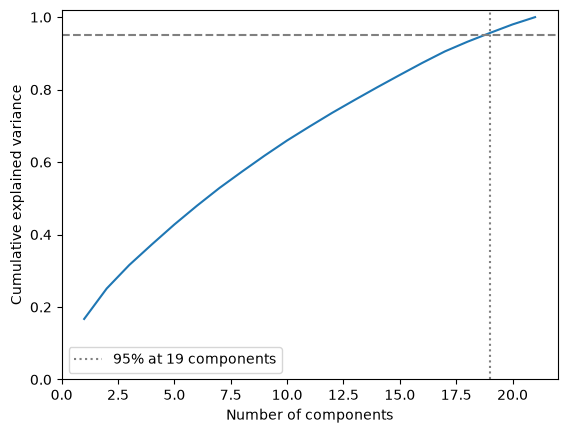

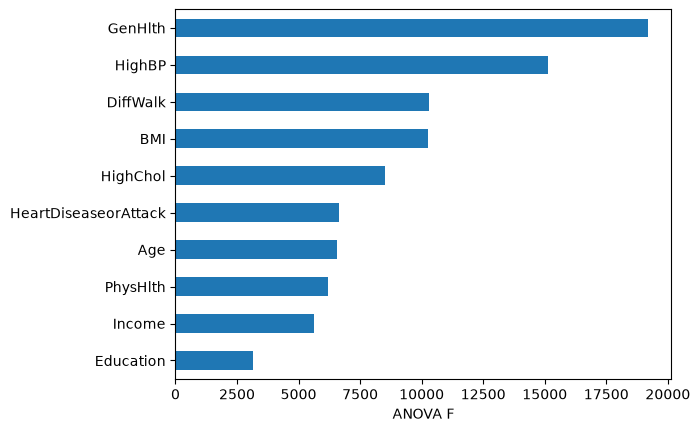

Highest ANOVA scores: GenHlth, HighBP, DiffWalk


In [6]:
mlw.plot_pca_explained_variance(X_train)
plt.show()
scores = mlw.compute_feature_scores(X_train, y_train)
mlw.plot_feature_scores(scores, top_n=10)
plt.show()
print("Highest ANOVA scores:", ", ".join(scores.index[:3]))

**Commentaire :** Il faut 19 composantes sur 21 pour conserver 95 % de la variance. Le gain en dimension est faible et les axes perdent le sens des indicateurs d’origine. La santé générale et l’hypertension figurent en tête du classement univarié. Cette association transversale ne permet pas une interprétation causale.

## 4. Model selection on training folds

Les cinq plis comparent une référence majoritaire, une régression logistique, un arbre de décision et un ensemble d’arbres entraînés séquentiellement (boosting). La médiane et la standardisation sont estimées dans chaque pli. Le meilleur réglage de chaque famille est ensuite réajusté sur tout l’entraînement. Pour chaque classifieur entraîné, les pondérations uniforme et équilibrée sont candidates. La précision moyenne départage les réglages.

In [7]:
SCORING = "average_precision"
cv_results, models = mlw.fit_candidates(
    X_train, y_train, scoring=SCORING,
    compare_weights=True,
)
winner = cv_results.iloc[0]["model"]
display(cv_results.round(4))
print("Selected on training folds:", winner)

,model,features,parameters,weights,CV mean,CV SD,precision,recall
18,Boosting,All features,{'model__max_leaf_nodes': 31},uniform,0.4357,0.0076,0.5873,0.1633
20,Boosting,All features,{'model__max_leaf_nodes': 31},balanced,0.4351,0.0079,0.3064,0.7954
17,Boosting,All features,{'model__max_leaf_nodes': 7},uniform,0.4319,0.0064,0.5731,0.1683
19,Boosting,All features,{'model__max_leaf_nodes': 7},balanced,0.4313,0.0065,0.3053,0.7972
1,Logistic,All features,{'model__C': 0.1},uniform,0.4076,0.0043,0.5390,0.1579
5,Logistic,All features,{'model__C': 1.0},uniform,0.4076,0.0043,0.5391,0.1580
3,Logistic,All features,{'model__C': 0.1},balanced,0.4060,0.0041,0.3118,0.7656
7,Logistic,All features,{'model__C': 1.0},balanced,0.4060,0.0041,0.3118,0.7656
14,Tree,All features,{'model__max_depth': 8},uniform,0.4029,0.0059,0.5511,0.1436
16,Tree,All features,{'model__max_depth': 8},balanced,0.4019,0.0059,0.2952,0.7842


Selected on training folds: Boosting


**Commentaire :** À poids uniformes, la régression sur les 21 variables atteint une AP moyenne de 0,408, contre 0,401 pour la sélection de dix variables et pour la PCA. La réduction simplifie la représentation, avec un léger recul du classement sur ces plis.

### Effet de la pondération sur le boosting

À complexité identique, la pondération modifie-t-elle le classement des répondants, ou surtout les décisions au seuil par défaut ? Les scores ci-dessous proviennent des mêmes cinq plis.

In [8]:
boosting = cv_results.loc[cv_results["model"] == "Boosting"]
chosen_structure = boosting.iloc[0]["parameters"]
paired = boosting.loc[boosting["parameters"] == chosen_structure]
display(paired[["weights", "parameters", "CV mean", "precision", "recall"]].round(4))

,weights,parameters,CV mean,precision,recall
18,uniform,{'model__max_leaf_nodes': 31},0.4357,0.5873,0.1633
20,balanced,{'model__max_leaf_nodes': 31},0.4351,0.3064,0.7954


**Commentaire :** Pour le boosting à 31 feuilles, équilibrer les poids fait passer le rappel moyen de 16,3 % à 79,5 % au seuil par défaut, tandis que la précision passe de 58,7 % à 30,6 %. L’AP reste proche (0,4357 avec poids uniformes, 0,4351 avec poids équilibrés). Cet écart de 0,0006 justifie peu de confiance dans une supériorité de classement. Le choix de pondération a surtout une conséquence sur les personnes qui déclenchent une alerte.

## 5. Held-out evaluation

,Majority,Logistic,Tree,Boosting
accuracy,0.8607,0.8622,0.8635,0.8656
balanced_accuracy,0.5000,0.5672,0.5612,0.5703
precision,0.0000,0.5178,0.5380,0.5623
recall,0.0000,0.1583,0.1422,0.1608
f1,0.0000,0.2425,0.2249,0.2501
f0.5,0.0000,0.3561,0.3456,0.3751
roc_auc,0.5000,0.8192,0.8144,0.8271
average_precision,0.1393,0.3942,0.3981,0.4250


,TN,FP,FN,TP
Majority,43667,0,7069,0
Logistic,42625,1042,5950,1119
Tree,42804,863,6064,1005
Boosting,42782,885,5932,1137


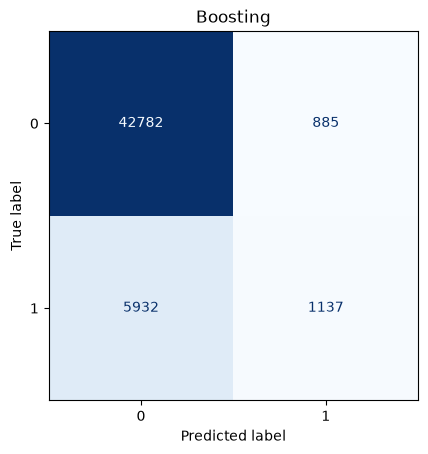

In [9]:
results = mlw.compare_models(models, X_test, y_test)
count_columns = ["TN", "FP", "FN", "TP"]
display(results.drop(columns=count_columns).T.round(4))
display(results[count_columns].astype(int))
mlw.plot_confusion_matrix(models[winner], X_test, y_test)
plt.title(winner)
plt.show()

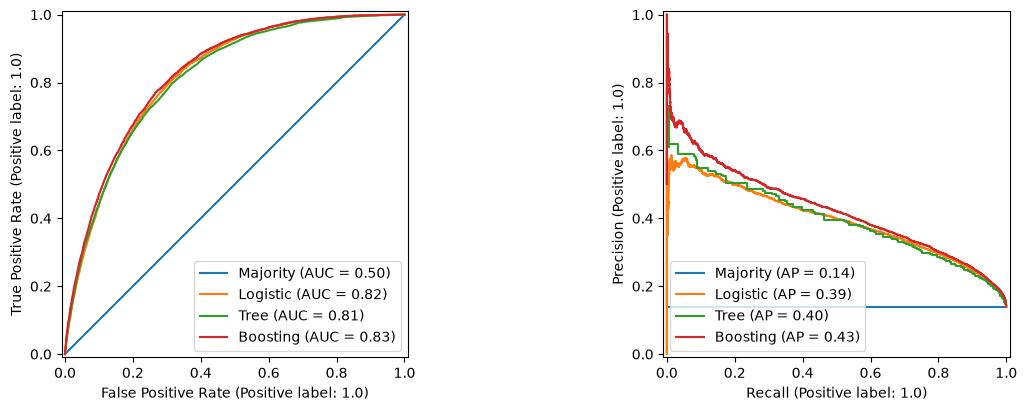

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
mlw.plot_roc_curves(models, X_test, y_test, ax=axes[0])
mlw.plot_precision_recall_curves(models, X_test, y_test, ax=axes[1])
plt.show()

## 6. Discussion

**Choix final.** Pour classer les répondants, le critère annoncé retient le boosting à 31 feuilles et poids uniformes. Sur le test, son AP de 0,425 dépasse celle de la régression (0,394), de l’arbre seul (0,398) et du score constant (0,139). Au seuil par défaut, il retrouve seulement 1 137 des 7 069 cas positifs, soit 16,1 %. Une bonne capacité de classement peut donc coexister avec un seuil qui laisse échapper la majorité des cas.

**Portée.** Un programme de dépistage devrait d’abord fixer une sensibilité cible et une capacité de suivi des alertes, puis vérifier son seuil dans une population indépendante. La cible et plusieurs indicateurs sont autodéclarés dans la même enquête. L’étude renseigne sur leur association en 2015. Une prédiction du risque futur demanderait un suivi longitudinal.